# Dynamic DeepHit: 5 final seeds, with vs. without actions in the input

Two variants, 5 seeds each:
- **with_actions**: fluid/vaso included in the inputs (latents intended for the RL *state*)
- **without_actions**: treatment removed from the inputs (health score intended for the RL *reward*)

This notebook generates train/val/test predictions for all 10 models (cached to each run's folder), evaluates discrimination/calibration across seeds, checks how consistent the reward is across seeds, and runs the vaso-onset event study.

In [1]:
import sys
import os
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

repo_root = Path("/home/jake/Documents/AI_Clinician/ai_clinician_pediatric_rl")
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.supervised_learning.predict as ddh_predict
import src.supervised_learning.evaluate_dynamic_deephit_final_seeds as eval_ddh
from src.rl.analysis import runs as an_runs, models as an_models, data as an_data

# hold registries, caches and settings (path mappings): never autoreload them;
# after editing either file, restart the kernel
%aimport -src.rl.analysis.runs
%aimport -src.rl.analysis.models

# Update prefixes for configuration loading

In [2]:
old_prefix = "/rds/general/user/jormond/home/projects/ai_clinician"
new_prefix = "/home/jake/Documents/AI_Clinician"

an_runs.set_path_mappings([
    (f"{old_prefix}/code", new_prefix),   # "code" and "data" folders don't exist locally
    (f"{old_prefix}/data", new_prefix),
    (old_prefix, new_prefix),
])

[('/rds/general/user/jormond/home/projects/ai_clinician/code',
  '/home/jake/Documents/AI_Clinician'),
 ('/rds/general/user/jormond/home/projects/ai_clinician/data',
  '/home/jake/Documents/AI_Clinician'),
 ('/rds/general/user/jormond/home/projects/ai_clinician',
  '/home/jake/Documents/AI_Clinician')]

# Load models

In [3]:
hospital = "choc"
unit = "picu"
DDH_ROOT = f"/home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/{hospital}/five_splits/split_0/sepsis/intake-vis/{unit}"

variant_dirs = {
    "with_actions": f"{DDH_ROOT}/with_actions/for_rewards",
    "without_actions": f"{DDH_ROOT}/without_actions/five_seeds",
}
for actions, d in variant_dirs.items():
    print(f"{actions}: {d}")

with_actions: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards
without_actions: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/without_actions/five_seeds


In [4]:
study = eval_ddh.make_ddh_study(variant_dirs)
actions_included = [k[0] for k in study.keys]

table = study.table(["include_actions_in_state", "actions_shift"])
table["run_folder"] = table["run_dir"].map(os.path.basename)
display(table.drop(columns=["run_dir", "data"]))

# full location of each variant's runs, once
for actions in actions_included:
    job_dirs = {os.path.dirname(r.run_dir) for r in study.group(actions).values()}
    print(f"{actions}: {', '.join(sorted(job_dirs))}")

Study 'ddh': 2 group(s), 10 run(s), seeds [0, 1, 2, 3, 4]
  between groups:
      _group                                   {'with_actions': 'with_actions', 'without_actions': 'without_actions'}
      actions_shift                            {'with_actions': False, 'without_actions': True}
      include_actions_in_state                 {'with_actions': 'True', 'without_actions': 'False'}
  OK


family include_actions_in_state  actions_shift  \
group           seed                                                            
with_actions    0     dynamic_deephit                     True          False   
                1     dynamic_deephit                     True          False   
                2     dynamic_deephit                     True          False   
                3     dynamic_deephit                     True          False   
                4     dynamic_deephit                     True          False   
without_actions 0     dynamic_deephit                    False           True   
                1     dynamic_deephit                    False           True   
                2     dynamic_deephit                    False           True   
                3     dynamic_deephit                    False           True   
                4     dynamic_deephit                    False           True   

                      n_overrides                                 run_folder  
group           seed                                                          
with_actions    0               0  unknown_cx3-20-5_20261008-223930_282892d6  
                1               0  unknown_cx3-20-5_20261008-230435_f843dcb3  
                2               0  unknown_cx3-20-5_20261008-232901_184b2158  
                3               0  unknown_cx3-20-5_20261008-235322_9218cdd3  
                4               0  unknown_cx3-20-5_20261009-000835_4cde6f06  
without_actions 0               0  unknown_cx3-20-6_20260925-181508_e9e84113  
                1               0  unknown_cx3-20-6_20260925-183253_6e5ca9a1  
                2               0  unknown_cx3-20-6_20260925-185554_557056b6  
                3               0  unknown_cx3-20-6_20260925-191923_f84ae180  
                4               0  unknown_cx3-20-6_20260925-193407_a894f673

with_actions: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7
without_actions: /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/without_actions/five_seeds/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20260925_181431_276322_job4167591.pbs-7


note that actions_shift in the without_actions model has no effect.

In [5]:
ddh_models = eval_ddh.load_ddh_models(study)   # {variant: {seed: LoadedModel}}, ordered by seed

config_managers = {actions: seeds[min(seeds)].config_manager for actions, seeds in ddh_models.items()}

# check the remapped paths point at local files
for actions, cm in config_managers.items():
    path = eval_ddh.dataset_filepath(cm, "test")
    print(f"{actions}: {path}  exists: {os.path.exists(path)}")

  loaded LoadedModel(ddh with_actions seed 0: model)
  loaded LoadedModel(ddh with_actions seed 1: model)
  loaded LoadedModel(ddh with_actions seed 2: model)
  loaded LoadedModel(ddh with_actions seed 3: model)
  loaded LoadedModel(ddh with_actions seed 4: model)
  loaded LoadedModel(ddh without_actions seed 0: model)
  loaded LoadedModel(ddh without_actions seed 1: model)
  loaded LoadedModel(ddh without_actions seed 2: model)
  loaded LoadedModel(ddh without_actions seed 3: model)
  loaded LoadedModel(ddh without_actions seed 4: model)
with_actions: /home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly_all_patients/split_0/training_set/test_picu_dynamic_deephit_dataset.h5  exists: True
without_actions: /home/jake/Documents/AI_Clinician/choc_data/combined_data/hourly_all_patients/split_0/training_set/test_picu_dynamic_deephit_dataset.h5  exists: True


# Load data

In [6]:
processors = eval_ddh.load_datasets(ddh_models, splits=("train", "val", "test"))

# generate predictions

In [9]:
actions_included = ['with_actions']

In [10]:

for actions in actions_included:
    eval_ddh.run_predictions(
        ddh_models[actions], processors,
        splits=("train", "val", "test"), batch_size=512
    )

train: 1680034 windows, 156 inputs, actions_shift=True
  verified 448 windows against Dataset.__getitem__
  seed 0: saved to /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7/unknown_cx3-20-5_20261008-223930_282892d6/train_predictions.h5
  seed 1: saved to /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7/unknown_cx3-20-5_20261008-230435_f843dcb3/train_predictions.h5
  seed 2: saved to /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_spl

In [ ]:
# plot the prediction trajectories for a few random patients from the test set, for each model
seeds_to_plot = [0, 1, 2, 3, 4] 
for actions in actions_included:
    for seed, m in ddh_models[actions].items():
        if seed not in seeds_to_plot:
            continue
        print(f"{actions} seed {seed}")
        ddh_predict.plot_random_predictions(m.config_manager)

# evaluate similarity of predictions

In [14]:
# Agreement across seeds (test split)
variant_dirs = {a: os.path.dirname(os.path.dirname(ddh_models[a][0][1].experiment_dir)) for a in actions_included}
ENSEMBLE_DIRS = {a: eval_ddh.ensemble_dir(ddh_models[a]) for a in actions_included}
for a, d in ENSEMBLE_DIRS.items():
    print(f"{a}: {d}")

agreement = {}
for actions in actions_included:
    hs_by_seed, meta = eval_ddh.load_health_scores(ddh_models[actions], split="test")
    agreement[actions] = eval_ddh.seed_agreement_summary(hs_by_seed, meta["index_ptr"])
    os.makedirs(ENSEMBLE_DIRS[actions], exist_ok=True)
    fig = eval_ddh.plot_seed_trajectories(
        hs_by_seed, meta, dataset=processors["test"], n_stays=6,
        save_path=os.path.join(ENSEMBLE_DIRS[actions], "seed_trajectories_test.png"),
    )
    print(actions)
    display(fig)

agreement_table = pd.concat(agreement, axis=1)
agreement_table.columns = actions_included
agreement_table.round(3)

TypeError: 'LoadedModel' object is not subscriptable

## these figures justify the ensemble directly. In a sentence: individual-seed hourly rewards share only about 35% of their variance, and averaging five seeds raises the shared component to about 73%, so all RL seeds are trained on the same, less noisy reward. The variants differ only marginally. The action-free version has slightly lower minimum agreement (0.27, between seeds 1 and 3), which doesn't change anything.


=== with_actions: health score Pearson across seeds (test) ===
       0      1      2      3      4
0  1.000  0.928  0.916  0.925  0.928
1  0.928  1.000  0.920  0.921  0.924
2  0.916  0.920  1.000  0.920  0.920
3  0.925  0.921  0.920  1.000  0.925
4  0.928  0.924  0.920  0.925  1.000
off-diagonal mean 0.923, min 0.916, max 0.928


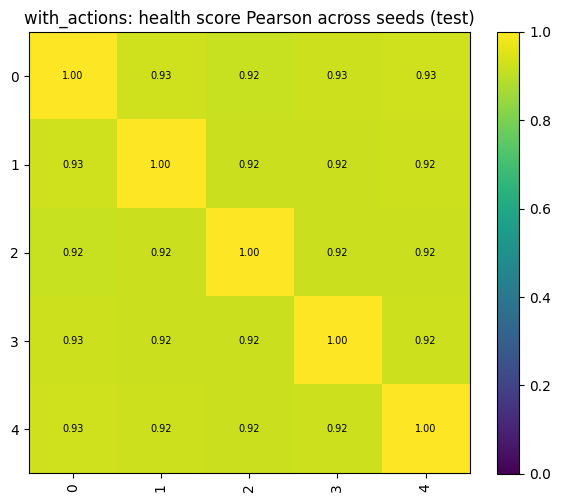


=== with_actions: reward Pearson across seeds (test) ===
       0      1      2      3      4
0  1.000  0.367  0.360  0.389  0.350
1  0.367  1.000  0.365  0.392  0.338
2  0.360  0.365  1.000  0.389  0.334
3  0.389  0.392  0.389  1.000  0.356
4  0.350  0.338  0.334  0.356  1.000
off-diagonal mean 0.364, min 0.334, max 0.392


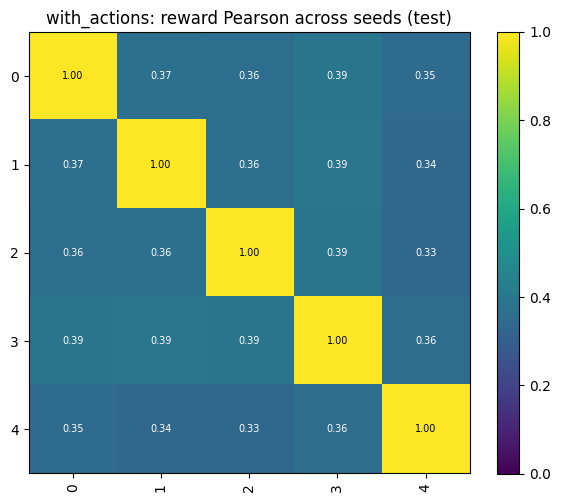

In [16]:
# Pairwise Pearson between seeds, printed for copying (test split)
for actions in actions_included:
    hs_by_seed, meta = eval_ddh.load_health_scores(ddh_models[actions], split="test")
    index_ptr = meta["index_ptr"]
    hs = {s: h for s, h in hs_by_seed.items()}
    rewards = {s: eval_ddh.within_stay_reward(h, index_ptr) for s, h in hs_by_seed.items()}

    for name, series in [("health score", hs), ("reward", rewards)]:
        pearson, _ = eval_ddh.pairwise_agreement(series)
        offdiag = pearson.values[~np.eye(len(pearson), dtype=bool)]
        print(f"\n=== {actions}: {name} Pearson across seeds (test) ===")
        print(pearson.round(3).to_string())
        print(f"off-diagonal mean {offdiag.mean():.3f}, min {offdiag.min():.3f}, max {offdiag.max():.3f}")
        display(eval_ddh.plot_agreement(pearson, f"{actions}: {name} Pearson across seeds (test)"))

# average the rewards

In [17]:
# Build the seed-averaged health score for every split
for actions in actions_included:
    for split in ["train", "val", "test"]:
        eval_ddh.build_ensemble_health_score(ddh_models[actions], split, processors[split])

train: ensemble of seeds [0, 1, 2, 3, 4] saved to /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7/train_predictions.h5
val: ensemble of seeds [0, 1, 2, 3, 4] saved to /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7/val_predictions.h5
test: ensemble of seeds [0, 1, 2, 3, 4] saved to /home/jake/Documents/AI_Clinician/models/dynamic_deephit_results/choc/five_splits/split_0/sepsis/intake-vis/picu/with_actions/for_rewards/choc_dynamic_deephit_transformer_discharge_mortality_tte_standard_split_0_20261008_223840_641745_job4295760.pbs-7/test_predictions.h5


In [19]:
for actions in actions_included:
    out_dir = eval_ddh.ensemble_dir(ddh_models[actions])
    for split in ["train", "val", "test"]:
        ens = eval_ddh.load_ensemble_health_score(eval_ddh.prediction_path(out_dir, split))
        n_rows = ens["index_ptr"][-1]
        print(f"{actions:16s} {split:5s} rows={n_rows:7d}  health_score={ens['health_score'].shape}  "
              f"seeds={list(ens['seeds'])}  matches rows: {len(ens['health_score']) == n_rows}")

with_actions     train rows=1680034  health_score=(1680034,)  seeds=[0, 1, 2, 3, 4]  matches rows: True
with_actions     val   rows= 376390  health_score=(376390,)  seeds=[0, 1, 2, 3, 4]  matches rows: True
with_actions     test  rows= 499032  health_score=(499032,)  seeds=[0, 1, 2, 3, 4]  matches rows: True


with_actions


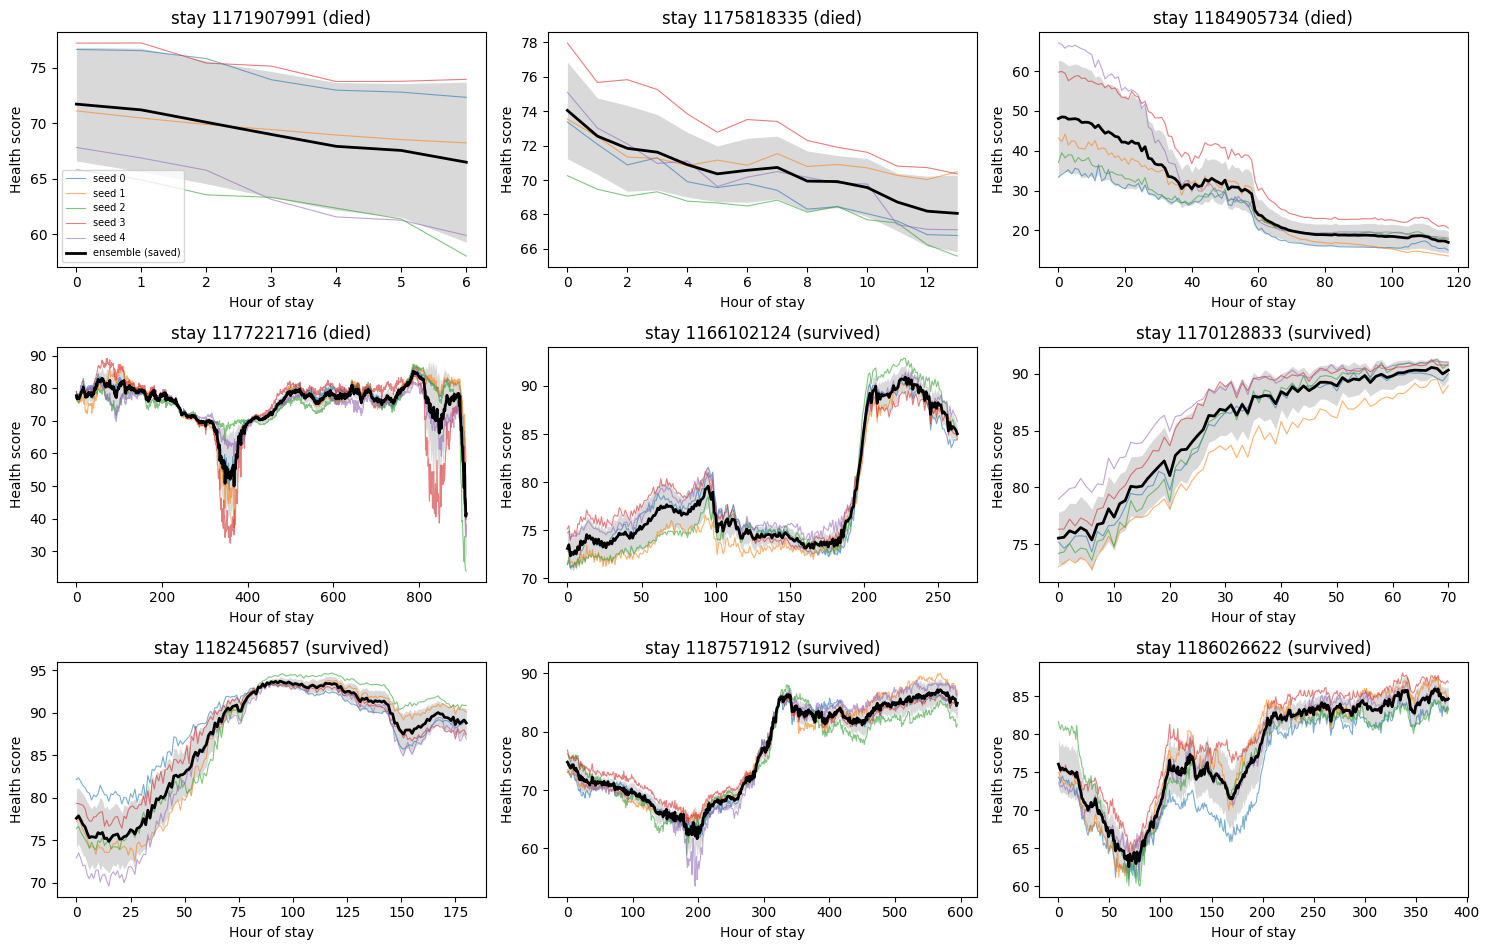

In [20]:
N_STAYS = 9
for actions in actions_included:
    hs_by_seed, meta = eval_ddh.load_health_scores(ddh_models[actions], split="test")
    out_dir = eval_ddh.ensemble_dir(ddh_models[actions])
    ensemble = eval_ddh.load_ensemble_health_score(eval_ddh.prediction_path(out_dir, "test"))

    fig = eval_ddh.plot_seed_trajectories(
        hs_by_seed, meta, dataset=processors["test"], ensemble=ensemble,
        n_stays=N_STAYS, rng_seed=0,
        save_path=os.path.join(out_dir, "seed_trajectories_with_ensemble_test.png"),
    )
    print(actions)
    display(fig)

# Config managers
Time bins are taken from `results.json` if saved there. Otherwise they come from the cohort/unit/filter_old lookup in the prediction branch of `supervised_learning.py`, which does **not** match the bins hardcoded in its `single_split` training branch; confirm which bins these models were trained with.

In [ ]:
all_run_dirs = [d for r in runs.values() for d in r.values()]
saved_time_bins = eval_ddh.training_time_bins(all_run_dirs)
print(f"Time bins from results.json: {saved_time_bins}")

TIME_BINS = saved_time_bins   # replace with the training bins if None, e.g. [0, 50, 103, 164, 237, 328, 460, 669, 1441]

config_managers = {
    variant: eval_ddh.build_config_manager(ARG_OVERRIDES, actions_in_state, time_bins=TIME_BINS)
    for variant, actions_in_state in eval_ddh.VARIANTS.items()
}
for variant, cm in config_managers.items():
    print(f"{variant}: actions_in_state={cm.training_config['actions_in_state']}, time_bins={cm.time_bins}")

# Sanity check: action features in the inputs
The action-free processor must contain no fluid/vaso-derived features (including `_mask` / `_delta` columns). The action names come from the with-actions `results.json`.

In [ ]:
first_with_run = next(iter(runs["with_actions"].values()))
ACTION_NAMES = eval_ddh.load_results_json(first_with_run)["hyperparameters"]["actions"]
print(f"Action names: {ACTION_NAMES}")

feature_names = {}
for variant, actions_in_state in eval_ddh.VARIANTS.items():
    print(f"\n{variant}:")
    feature_names[variant] = eval_ddh.check_action_features(
        config_managers[variant], ACTION_NAMES, expect_present=actions_in_state
    )

# Predictions
Generates train/val/test predictions for every seed (skipped where the `.h5` already exists). Train/val are written to disk for the RL pipeline; only test is kept in memory.

In [ ]:
test_predictions = {}
for variant in eval_ddh.VARIANTS:
    preds = eval_ddh.run_predictions(config_managers[variant], runs[variant], MODEL_TYPE)
    for seed in preds:
        test_predictions[(variant, seed)] = preds[seed]["test"]

In [ ]:
# test dataset (labels, trajectories) - shared by both variants, checked for alignment
test_dataset = eval_ddh.load_dataset(config_managers["with_actions"], split="test")
for key, preds in test_predictions.items():
    eval_ddh.check_alignment(preds, test_dataset)
print("All predictions aligned with the test dataset.")
index_ptr = np.asarray(test_dataset["index_ptr"])

# Discrimination and calibration (bootstrap)
Uses `bootstrap_evaluation_all_samples` rather than `predict.bootstrap_evaluation`, which saves only the last bootstrap sample. Resampling is by stay, since hourly rows within a stay are correlated. `seed_sd` is the between-seed spread; the pooled interval combines bootstrap and seed variability.

In [ ]:
N_BOOTSTRAP = 100
RESAMPLE_UNIT = "stay"

boot_by_model = {}
for (variant, seed), preds in test_predictions.items():
    print(f"Bootstrapping {variant} seed {seed}...")
    boot_by_model[(variant, seed)] = eval_ddh.bootstrap_evaluation_all_samples(
        preds, test_dataset,
        n_bootstrap_samples=N_BOOTSTRAP,
        resample_unit=RESAMPLE_UNIT,
        rng_seed=seed,
        save_dir=runs[variant][seed],
    )

boot_long, boot_summary = eval_ddh.summarise_bootstrap(boot_by_model)
boot_summary.to_csv(os.path.join(SAVE_DIR, f"bootstrap_summary_{RESAMPLE_UNIT}.csv"), index=False)

In [ ]:
# side-by-side comparison of the two variants
comparison = boot_summary.pivot(index="metric", columns="variant", values=["seed_mean", "seed_sd"])
comparison.columns = [f"{variant}_{stat}" for stat, variant in comparison.columns]
comparison["difference_without_minus_with"] = (
    comparison["without_actions_seed_mean"] - comparison["with_actions_seed_mean"]
)
pd.set_option("display.max_rows", 200)
comparison.round(4)

# Health score distributions per seed
Existing `plot_health_score_statistics` (death vs. survival KDEs and Mann-Whitney tests), saved to each run folder. Deaths should score lower; if not, check the head order assumed in `calculate_comprehensive_health_score`.

In [ ]:
for variant in eval_ddh.VARIANTS:
    for seed, run_dir in runs[variant].items():
        print(f"\n{variant} seed {seed}")
        ddh_predict.plot_health_score_statistics(eval_ddh.for_run(config_managers[variant], run_dir))

# Example patient trajectories
Writes ~100 plots per run, so restricted to selected seeds.

In [ ]:
PLOT_SEEDS = [list(runs["with_actions"])[0]]

for variant in eval_ddh.VARIANTS:
    for seed in PLOT_SEEDS:
        ddh_predict.plot_random_predictions(eval_ddh.for_run(config_managers[variant], runs[variant][seed]))

# Reward agreement across seeds
If the action-free rewards are highly correlated across seeds, the choice of reward seed matters little. The with vs. without comparison shows how much removing treatment changes the reward.

In [ ]:
health_scores = {key: np.asarray(p["health_score"]) for key, p in test_predictions.items()}
rewards = {key: eval_ddh.within_stay_reward(hs, index_ptr) for key, hs in health_scores.items()}

for name, series in [("health_score", health_scores), ("reward", rewards)]:
    pearson, spearman = eval_ddh.pairwise_agreement(series)
    pearson.to_csv(os.path.join(SAVE_DIR, f"{name}_pearson_across_models.csv"))
    spearman.to_csv(os.path.join(SAVE_DIR, f"{name}_spearman_across_models.csv"))
    fig = eval_ddh.plot_agreement(
        spearman, f"{name}: Spearman correlation across models (test)",
        save_path=os.path.join(SAVE_DIR, f"{name}_spearman_across_models.png"),
    )
    display(fig)

In [ ]:
# summary: mean off-diagonal correlation within each variant and between variants
_, reward_spearman = eval_ddh.pairwise_agreement(rewards)
labels = reward_spearman.index
is_with = labels.str.startswith("with_actions")
is_without = labels.str.startswith("without_actions")

def mean_offdiag(mask_rows, mask_cols):
    block = reward_spearman.values[np.ix_(mask_rows, mask_cols)]
    if np.array_equal(mask_rows, mask_cols):
        block = block[~np.eye(block.shape[0], dtype=bool)]
    return block.mean()

print(f"Reward Spearman, within with_actions:    {mean_offdiag(is_with, is_with):.3f}")
print(f"Reward Spearman, within without_actions: {mean_offdiag(is_without, is_without):.3f}")
print(f"Reward Spearman, between variants:       {mean_offdiag(is_with, is_without):.3f}")

# Vaso-onset event study
Hour 0 is the first hour with nonzero vaso. That dose is masked in the final input row, so the action-aware model first sees it at hour +1. A step at +1 present only in the with-actions curves is the input-leak signature; a decline that starts before hour 0 in both variants reflects the deterioration that prompted treatment (confounding by indication).

Onsets use the full test cohort of this dataset, not only sepsis stays. Check the printed firing fraction: zero dose is assumed to be the minimum of the normalised vaso column.

In [ ]:
print([f for f in feature_names["with_actions"] if any(f.startswith(a) for a in ACTION_NAMES)])
VASO_FEATURE = ACTION_NAMES[1]   # CHECK: the vaso dose column itself, not its _mask/_delta
PRE_HOURS, POST_HOURS = 12, 24

onsets = eval_ddh.find_vaso_onsets(test_dataset, VASO_FEATURE, min_pre_hours=PRE_HOURS)

In [ ]:
fig = eval_ddh.plot_event_study(
    health_scores, index_ptr, onsets,
    pre=PRE_HOURS, post=POST_HOURS,
    save_path=os.path.join(SAVE_DIR, "vaso_onset_event_study.png"),
)
fig